# Project summary
> Can EEG activity in a specific time window predict the participant’s perceived emotion, separately within each ambiguity level?


1. Decoding fear or happy with binary classification within each ambiguity level

2. Cross-decoding to test generalization of ambiguity level

    a. Training emotion classification using low ambiguity trials only

    b. Apply this trained model to high ambiguity trials.

    c. Evaluate the accuracy. If accuracy is still high, the emotion code is stable.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import mne
import os
import re
import scipy.io as sio
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.base import clone
from mne.decoding import CSP
from mne.time_frequency import tfr_morlet
from mne.preprocessing import ICA
from collections import defaultdict, deque

`pip install pandas numpy scikit-learn matplotlib seaborn openpyxl`

`pip install mne pandas scikit-learn openpyxl matplotlib`

In [2]:
path = "03 EEG Data and Code/FearHappyJudgment_Behavior and LPP.xlsx"

df = pd.read_excel(path).iloc[:, :5]

df.head()

,subID,codeL,vResp,RT,LPP
0,1,2,0,1143,1.747909
1,1,3,0,1233,5.892490
2,1,2,0,1195,4.262819
3,1,6,1,1115,2.531541
4,1,4,0,1214,-2.017248


`subID`: participant

`codeL`: morph level (1–7)

`vResp`: participant decision

`RT`: response time

`LPP`: EEG amplitude

# Check Behavior and LPP data
Morph level (1 happy → 7 fear)

- low ambiguity      : 1,7

- medium ambiguity   : 2,3,5,6

- high ambiguity     : 4

,subID,codeL,vResp,RT,LPP,ambiguity
0,1,2,0,1143,1.747909,medium
1,1,3,0,1233,5.892490,medium
2,1,2,0,1195,4.262819,medium
3,1,6,1,1115,2.531541,medium
4,1,4,0,1214,-2.017248,high


ambiguity
high       565
low       1137
medium    2301
dtype: int64

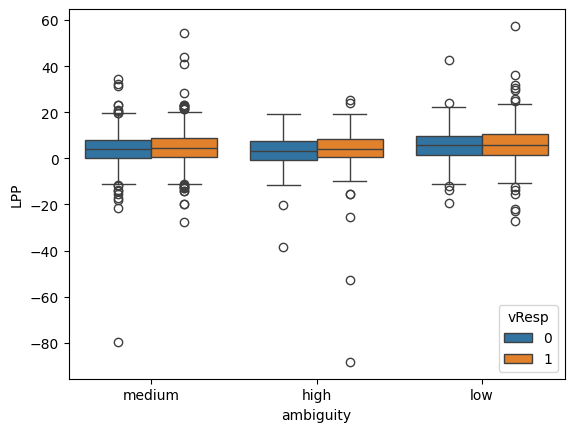

In [3]:
# Bin the codeL values into low, medium, and high ambiguity
# Check the distribution of codeL values
def ambiguity_bin(code):
    if code in [1,7]:
        return "low"
    if code in [2,3,5,6]:
        return "medium"
    if code == 4:
        return "high"

df["ambiguity"] = df["codeL"].apply(ambiguity_bin)
display(df.head())
display(df.groupby("ambiguity").size())

sns.boxplot(data=df, x="ambiguity", y="LPP", hue="vResp")
plt.show()

# Preprocessing
Use **perceived valence** from `vResp (fear=1, happy=0)` in behaviorData.mat instead of objective EEG-side valence.

E.g. EEG tags `B7(17)` are decoded as `codeI=1`(face ID) and `codeL=7` (face level), then matched to behavior trials by `codeI, codeL` using FIFO order.

All morph levels 1–7 are now included in training and evaluation.

### 1. Load EEG subject

In [4]:
eeg_path = "03 EEG Data and Code/MainTask_ShortEpoch"
# eeg_path = "03 EEG Data and Code/MainTask_LongEpoch"
behavior_mat_path = "02 Behavioral Data and Code/behaviorData.mat"

In [5]:
file = os.path.join(eeg_path, "sub1ar.set")
epochs = mne.io.read_epochs_eeglab(file)
epochs


Extracting parameters from /Users/grantsfolder/Desktop/COGS 189/COGS189_Face_emotion_EEG/03 EEG Data and Code/MainTask_ShortEpoch/sub1ar.set...
Not setting metadata
203 matching events found
No baseline correction applied
0 projection items activated
Ready.


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline off), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

### 2. Extract Morph Levels
* vResp:  button press 1 happy; 2 fear.
* codeI: Face ID
* codeL: 7 (decreasing) fearful levels (1 happiest; 7 most fearful)

Goal output: y==0 happy, y==1 fear


In [6]:
# Parse EEG event labels to extract codeI (face ID) and codeL (morph level) per trial
# Example: B7(17) -> codeI=1, codeL=7

inv_event_id = {v: k for k, v in epochs.event_id.items()}
events = epochs.events[:, 2]
event_names = [inv_event_id[e] for e in events]

event_codeI = []
event_codeL = []

for name in event_names:
    m = re.search(r"\((\d+)(\d)\)", name)
    if m is None:
        raise ValueError(f"Cannot parse event name: {name}")
    code_i = int(m.group(1))
    code_l = int(m.group(2))
    event_codeI.append(code_i)
    event_codeL.append(code_l)

event_codeI = np.array(event_codeI)
morph_levels = np.array(event_codeL)

print("Unique morph levels in EEG:", np.unique(morph_levels, return_counts=True))
print("Unique face IDs in EEG:", np.unique(event_codeI, return_counts=True))

Unique morph levels in EEG: (array([1, 2, 3, 4, 5, 6, 7]), array([29, 32, 30, 28, 30, 24, 30]))
Unique face IDs in EEG: (array([1, 2, 3, 4]), array([51, 48, 51, 53]))


In [7]:
# Load perceived responses from behaviorData.mat and align to EEG events
mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

# Get subject number from EEG filename: sub1ar.set -> 1
sub_match = re.search(r"sub(\d+)", os.path.basename(file))
if sub_match is None:
    raise ValueError(f"Could not infer subject ID from filename: {file}")
sub_id = int(sub_match.group(1))

sub_beh = eeg_data[sub_id - 1]  # matlab is 1-indexed; python is 0-indexed
beh_codeI = np.asarray(sub_beh.codeI).astype(int)
beh_codeL = np.asarray(sub_beh.codeL).astype(int)
beh_vResp = np.asarray(sub_beh.vResp).astype(int)

print(f"Subject {sub_id}: behavior trials = {len(beh_vResp)}, EEG trials = {len(morph_levels)}")

# Build FIFO queues for perceived responses keyed by (codeI, codeL)
resp_queue = defaultdict(deque)
for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
    resp_queue[(ci, cl)].append(vr)

# Match each EEG trial to perceived response using codeI + codeL
matched_vResp = []
missing = 0
for ci, cl in zip(event_codeI, morph_levels):
    key = (int(ci), int(cl))
    if len(resp_queue[key]) == 0:
        matched_vResp.append(np.nan)
        missing += 1
    else:
        matched_vResp.append(resp_queue[key].popleft())

matched_vResp = np.asarray(matched_vResp, dtype=float)
print(f"Matched EEG trials: {np.sum(~np.isnan(matched_vResp))}/{len(matched_vResp)}")
print(f"Unmatched EEG trials: {missing}")

Subject 1: behavior trials = 252, EEG trials = 203
Matched EEG trials: 203/203
Unmatched EEG trials: 0


### 3. Extract emotion and ambiguity labels

In [8]:
# Keep only trials that were successfully matched to behavior data
valid_mask = ~np.isnan(matched_vResp)

epochs = epochs[valid_mask]
event_codeI = event_codeI[valid_mask]
morph_levels = morph_levels[valid_mask]
matched_vResp = matched_vResp[valid_mask].astype(int)

# Perceived valence label from behavior
y = np.zeros(len(matched_vResp), dtype=int)
y[matched_vResp == 2] = 1

print("Final trial count:", len(y))
print("Label counts (0=happy, 1=fear):", np.unique(y, return_counts=True))

Final trial count: 203
Label counts (0=happy, 1=fear): (array([0, 1]), array([ 90, 113]))


In [9]:
def ambiguity_bin(code):
    if code in [1, 7]:
        return "low"
    elif code in [2, 3, 5, 6]:
        return "medium"
    elif code == 4:
        return "high"
    return "unknown"

ambiguity = np.array([ambiguity_bin(c) for c in morph_levels])
ambiguity_count = np.unique(ambiguity, return_counts=True)
[(str(ambiguity_count[0][i]) + ": " + str(ambiguity_count[1][i])) for i in range(3)]

['high: 28', 'low: 59', 'medium: 116']

# Exploratory analysis

In [10]:
epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=40.)
epochs_filt.apply_baseline((-0.2, 0))

Setting up band-pass filter from 0.1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 16501 samples (33.002 s)



/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_43404/919858817.py:1: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=40.)


Applying baseline correction (mode: mean)


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline -0.2 – 0 s), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

## ERP comparison

| Component | Time | Location | Meaning |
|---|---|---|---|
| P1 | 80–120 ms | occipital | early visual |
| N170 | 140–200 ms | P7/P8 | face processing |
| LPP | 300–600 ms | centroparietal | emotional evaluation |

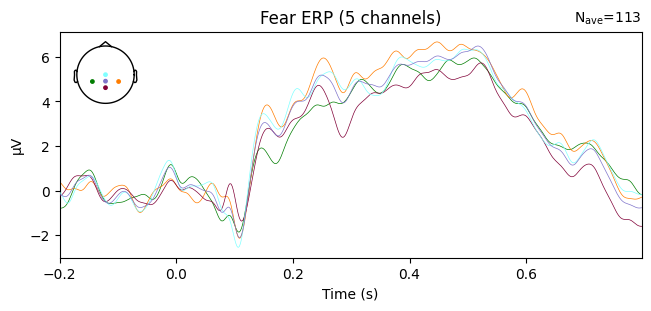

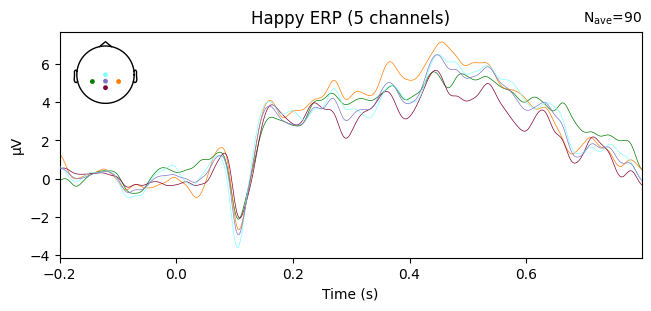

combining channels using "mean"
combining channels using "mean"


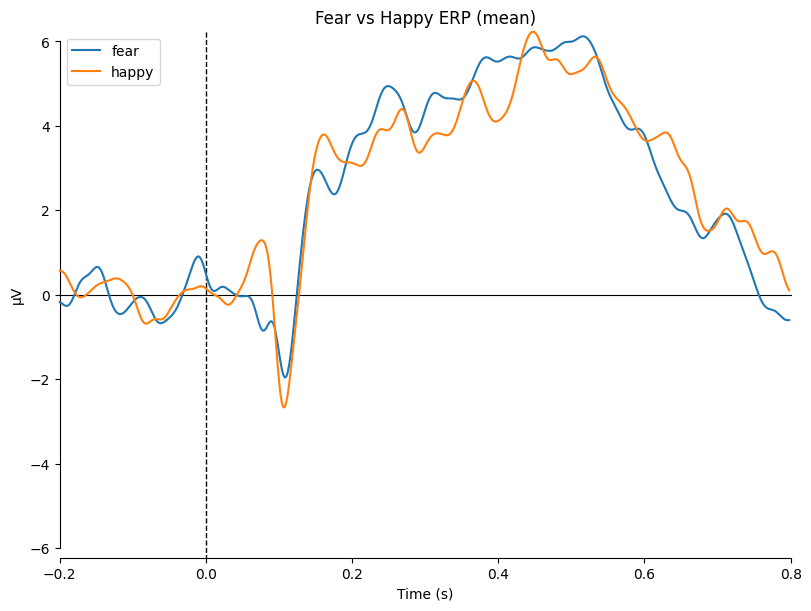

[<Figure size 800x600 with 1 Axes>]

In [11]:
# Separate conditions
epochs_fear = epochs_filt[y == 1]
epochs_happy = epochs_filt[y == 0]

# Compute evoked averages
evoked_fear = epochs_fear.average()
evoked_happy = epochs_happy.average()

# Plot ERP comparison
# picks = ['P7','P8','PZ','OZ','CZ']
picks = ['CP3','CP4','PZ','CZ','CPZ']

evoked_fear.plot(picks=picks, spatial_colors=True, titles="Fear ERP")
evoked_happy.plot(picks=picks, spatial_colors=True, titles="Happy ERP")

# Overlay comparison
mne.viz.plot_compare_evokeds(
    {"fear": evoked_fear, "happy": evoked_happy},
    picks=picks,
    combine="mean",
    title="Fear vs Happy ERP"
)

## Time–frequency analysis (STFT / Morlet)
### Difference spectrogram

| Band            | Interpretation           |
|-----------------|--------------------------|
| theta (4–7 Hz)  | emotion processing       |
| alpha (8–12 Hz) | attentional suppression  |
| beta (13–30 Hz) | cognitive evaluation     |

In [12]:
freqs = np.arange(4, 40, 2)  # frequency bands
n_cycles = freqs / 2

power = tfr_morlet(
    epochs_filt,
    freqs=freqs,
    n_cycles=n_cycles,
    return_itc=False,
    average=False
)

power_fear = power[y == 1]
power_happy = power[y == 0]

avg_fear = power_fear.average()
avg_happy = power_happy.average()

NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").


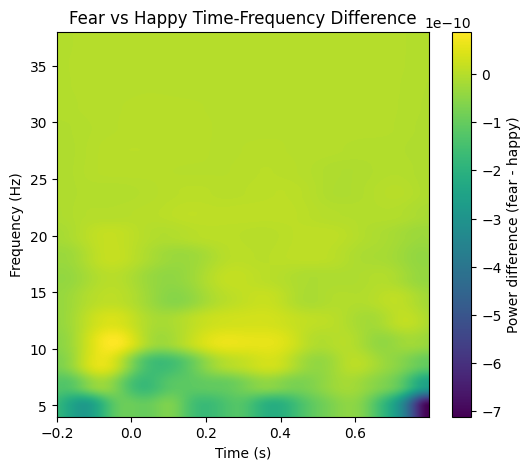

In [13]:
diff = avg_fear.data - avg_happy.data

plt.figure(figsize=(6,5))

plt.imshow(
    diff.mean(axis=0),
    aspect="auto",
    origin="lower",
    extent=[epochs.times[0], epochs.times[-1], freqs[0], freqs[-1]]
)

plt.colorbar(label="Power difference (fear - happy)")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Fear vs Happy Time-Frequency Difference")

plt.show()

# Average ERP

Subject 1: included (fear=113, happy=90)
Subject 2: included (fear=72, happy=130)
Subject 3: included (fear=93, happy=94)
Subject 4: included (fear=71, happy=119)
Subject 5: included (fear=88, happy=81)
Subject 6: included (fear=114, happy=92)
Subject 7: file not found, skipped
Subject 8: included (fear=83, happy=85)
Subject 9: included (fear=108, happy=119)
Subject 10: included (fear=64, happy=144)
Subject 11: included (fear=62, happy=140)
Subject 12: included (fear=51, happy=82)
Subject 13: included (fear=88, happy=132)
Subject 14: included (fear=100, happy=94)
Subject 15: included (fear=105, happy=86)
Subject 16: included (fear=82, happy=129)
Subject 17: included (fear=81, happy=154)
Subject 18: included (fear=121, happy=93)
Subject 19: included (fear=106, happy=121)
Subject 20: included (fear=107, happy=133)
Subject 21: included (fear=47, happy=38)
Subject 22: included (fear=78, happy=131)
Subject 23: included (fear=79, happy=75)
Included subjects for group plots: 22
Identifying co

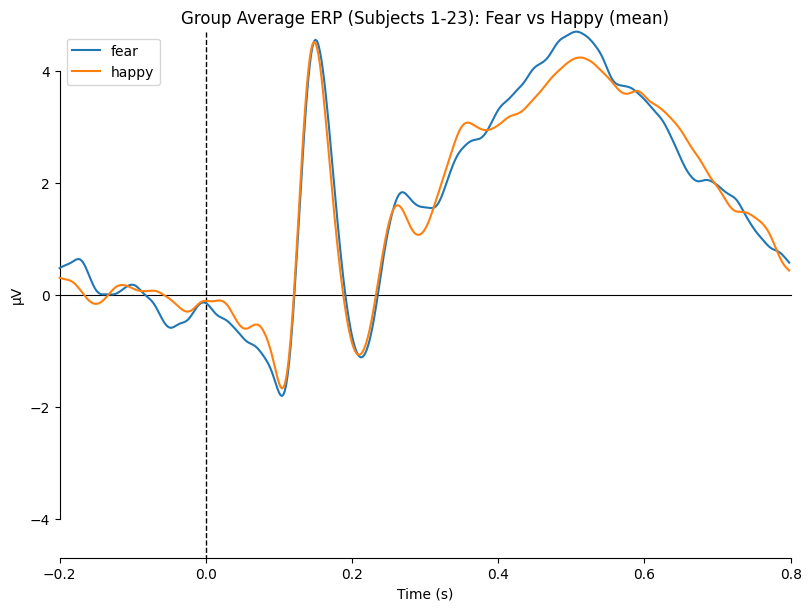

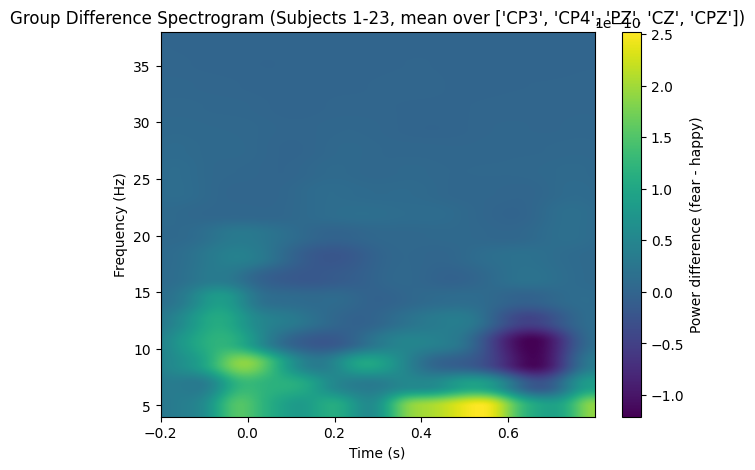

In [14]:
# Group average ERP + difference spectrogram (first 10 subjects)

range_min = 1
range_max = 23
# group_picks = ['P7','P8','PZ','OZ','CZ']
group_picks = ['CP3','CP4','PZ','CZ','CPZ']
# group_picks = ['P7','P8']
subject_ids = range(range_min, range_max + 1)

# Use same frequency settings as exploratory TFR, define if not present
if 'freqs' not in globals():
    freqs = np.arange(4, 40, 2)
if 'n_cycles' not in globals():
    n_cycles = freqs / 2

mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

evoked_fear_list = []
evoked_happy_list = []
tfr_diff_data_list = []
tfr_times = None

def _extract_codes_from_epochs(ep):
    inv_event_id = {v: k for k, v in ep.event_id.items()}
    events = ep.events[:, 2]
    event_names = [inv_event_id[e] for e in events]

    event_codeI_local = []
    morph_levels_local = []
    for name in event_names:
        m = re.search(r"\((\d+)(\d)\)", name)
        if m is None:
            raise ValueError(f"Cannot parse event name: {name}")
        event_codeI_local.append(int(m.group(1)))
        morph_levels_local.append(int(m.group(2)))

    return np.array(event_codeI_local), np.array(morph_levels_local)

for sub_id in subject_ids:
    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    if not os.path.exists(file):
        print(f"Subject {sub_id}: file not found, skipped")
        continue

    try:
        epochs_sub = mne.io.read_epochs_eeglab(file, verbose=False)
    except Exception as e:
        print(f"Subject {sub_id}: load failed ({e}), skipped")
        continue

    event_codeI_sub, morph_levels_sub = _extract_codes_from_epochs(epochs_sub)

    sub_beh = eeg_data[sub_id - 1]
    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    resp_queue = defaultdict(deque)
    for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
        resp_queue[(ci, cl)].append(vr)

    matched_vResp = []
    for ci, cl in zip(event_codeI_sub, morph_levels_sub):
        key = (int(ci), int(cl))
        if len(resp_queue[key]) == 0:
            matched_vResp.append(np.nan)
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.asarray(matched_vResp, dtype=float)
    valid_mask = ~np.isnan(matched_vResp)

    if valid_mask.sum() == 0:
        print(f"Subject {sub_id}: no matched trials, skipped")
        continue

    epochs_sub = epochs_sub[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)

    y_sub = np.zeros(len(matched_vResp), dtype=int)
    y_sub[matched_vResp == 2] = 1  # fear=1, happy=0

    fear_mask = y_sub == 1
    happy_mask = y_sub == 0

    if fear_mask.sum() == 0 or happy_mask.sum() == 0:
        print(f"Subject {sub_id}: missing one class, skipped")
        continue

    # Use IIR filtering to avoid very long FIR kernels on short epochs
    epochs_sub = epochs_sub.copy().filter(
        l_freq=0.1,
        h_freq=40.,
        method='iir',
        iir_params={'order': 4, 'ftype': 'butter'},
        verbose=False
    )
    epochs_sub.apply_baseline((-0.2, 0), verbose=False)
    epochs_sub = epochs_sub.copy().pick(group_picks, verbose=False)

    evoked_fear_sub = epochs_sub[fear_mask].average()
    evoked_happy_sub = epochs_sub[happy_mask].average()
    evoked_fear_list.append(evoked_fear_sub)
    evoked_happy_list.append(evoked_happy_sub)

    # Replace legacy tfr_morlet() with the modern API
    tfr_fear_sub = epochs_sub[fear_mask].compute_tfr(
        method='morlet',
        freqs=freqs,
        n_cycles=n_cycles,
        return_itc=False,
        average=True,
        verbose=False
    )
    tfr_happy_sub = epochs_sub[happy_mask].compute_tfr(
        method='morlet',
        freqs=freqs,
        n_cycles=n_cycles,
        return_itc=False,
        average=True,
        verbose=False
    )

    tfr_diff_data_list.append(tfr_fear_sub.data - tfr_happy_sub.data)
    tfr_times = tfr_fear_sub.times

    print(f"Subject {sub_id}: included (fear={fear_mask.sum()}, happy={happy_mask.sum()})")

print(f"Included subjects for group plots: {len(evoked_fear_list)}")

if len(evoked_fear_list) > 0:
    group_evoked_fear = mne.grand_average(evoked_fear_list)
    group_evoked_happy = mne.grand_average(evoked_happy_list)

    mne.viz.plot_compare_evokeds(
        {"fear": group_evoked_fear, "happy": group_evoked_happy},
        picks=group_picks,
        combine='mean',
        title=f"Group Average ERP (Subjects {range_min}-{range_max}): Fear vs Happy"
    )

if len(tfr_diff_data_list) > 0:
    group_tfr_diff = np.mean(np.stack(tfr_diff_data_list, axis=0), axis=0)  # ch x f x t
    group_tfr_diff_mean_ch = group_tfr_diff.mean(axis=0)  # f x t

    plt.figure(figsize=(7, 5))
    plt.imshow(
        group_tfr_diff_mean_ch,
        aspect='auto',
        origin='lower',
        extent=[tfr_times[0], tfr_times[-1], freqs[0], freqs[-1]]
    )
    plt.colorbar(label='Power difference (fear - happy)')
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title(f'Group Difference Spectrogram (Subjects {range_min}-{range_max}, mean over {group_picks})')
    plt.show()

Subject 1: processed
Subject 2: processed
Subject 3: processed
Subject 4: processed
Subject 5: processed
Subject 6: processed
Subject 7: file not found, skipped
Subject 8: processed
Subject 9: processed
Subject 10: processed
Subject 11: processed
Subject 12: processed
Subject 13: processed
Subject 14: processed
Subject 15: processed
Subject 16: processed
Subject 17: processed
Subject 18: processed
Subject 19: processed
Subject 20: processed
Subject 21: processed
Subject 22: processed
Subject 23: processed
Identifying common channels ...
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


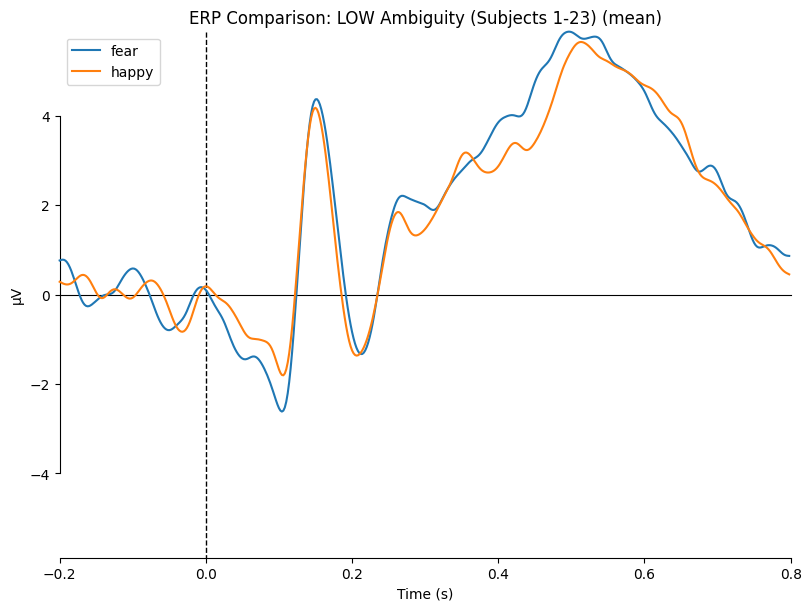

LOW: fear trials=22, happy trials=22
Identifying common channels ...
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


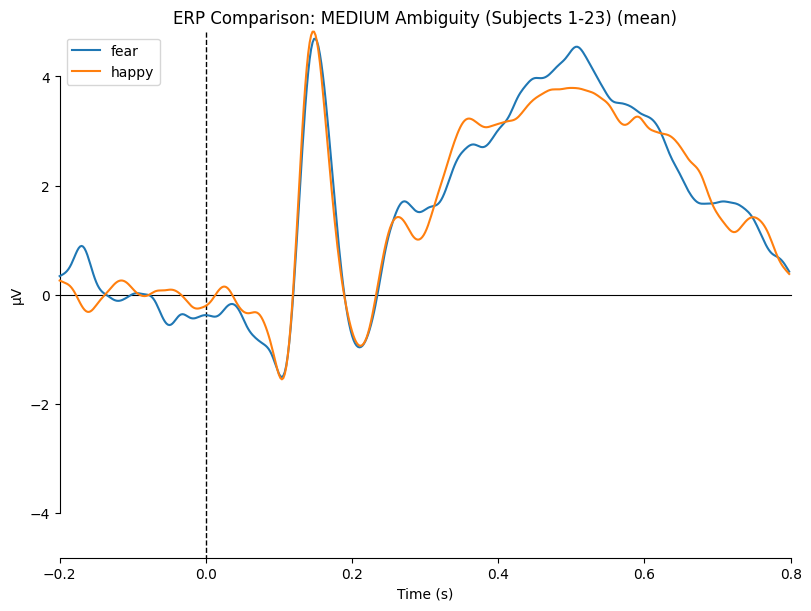

MEDIUM: fear trials=22, happy trials=22
Identifying common channels ...
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


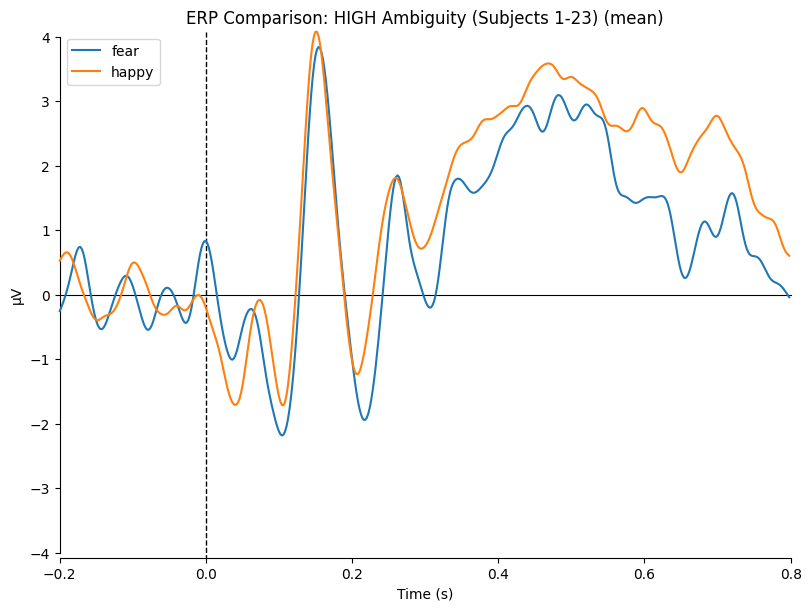

HIGH: fear trials=21, happy trials=22


In [15]:
# Compare fear vs happy within each ambiguity level across all subjects

range_min = 1
range_max = 23
group_picks = ['CP3', 'CP4', 'PZ', 'CZ', 'CPZ']
subject_ids = range(range_min, range_max + 1)

def ambiguity_bin(code):
    if code in [1, 7]:
        return "low"
    elif code in [2, 3, 5, 6]:
        return "medium"
    elif code == 4:
        return "high"
    return "unknown"

# Storage for group evoked responses by ambiguity
group_evoked_by_ambiguity = {
    "low": {"fear": [], "happy": []},
    "medium": {"fear": [], "happy": []},
    "high": {"fear": [], "happy": []}
}

mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

for sub_id in subject_ids:
    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    if not os.path.exists(file):
        print(f"Subject {sub_id}: file not found, skipped")
        continue

    try:
        epochs_sub = mne.io.read_epochs_eeglab(file, verbose=False)
    except Exception as e:
        print(f"Subject {sub_id}: load failed ({e}), skipped")
        continue

    # Extract codes from EEG events
    event_codeI_sub, morph_levels_sub = _extract_codes_from_epochs(epochs_sub)

    # Load behavior data
    sub_beh = eeg_data[sub_id - 1]
    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    # Match EEG trials to behavior using (codeI, codeL) FIFO queue
    resp_queue = defaultdict(deque)
    for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
        resp_queue[(ci, cl)].append(vr)

    matched_vResp = []
    for ci, cl in zip(event_codeI_sub, morph_levels_sub):
        key = (int(ci), int(cl))
        if len(resp_queue[key]) == 0:
            matched_vResp.append(np.nan)
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.asarray(matched_vResp, dtype=float)
    valid_mask = ~np.isnan(matched_vResp)

    if valid_mask.sum() == 0:
        print(f"Subject {sub_id}: no matched trials, skipped")
        continue

    # Keep only valid trials
    epochs_sub = epochs_sub[valid_mask]
    morph_levels_sub = morph_levels_sub[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)

    # Convert response to label: 0=happy, 1=fear
    y_sub = np.zeros(len(matched_vResp), dtype=int)
    y_sub[matched_vResp == 2] = 1

    # Determine ambiguity level for each trial
    ambiguity_sub = np.array([ambiguity_bin(c) for c in morph_levels_sub])

    # Preprocess
    epochs_sub = epochs_sub.copy().filter(
        l_freq=0.1,
        h_freq=40.,
        method='iir',
        iir_params={'order': 4, 'ftype': 'butter'},
        verbose=False
    )
    epochs_sub.apply_baseline((-0.2, 0), verbose=False)
    epochs_sub = epochs_sub.copy().pick(group_picks, verbose=False)

    # For each ambiguity level, compute evoked responses for fear and happy
    for ambiguity_level in ["low", "medium", "high"]:
        level_mask = ambiguity_sub == ambiguity_level
        fear_mask = (y_sub == 1) & level_mask
        happy_mask = (y_sub == 0) & level_mask

        if fear_mask.sum() > 0:
            evoked_fear = epochs_sub[fear_mask].average()
            group_evoked_by_ambiguity[ambiguity_level]["fear"].append(evoked_fear)

        if happy_mask.sum() > 0:
            evoked_happy = epochs_sub[happy_mask].average()
            group_evoked_by_ambiguity[ambiguity_level]["happy"].append(evoked_happy)

    print(f"Subject {sub_id}: processed")

# Grand average for each ambiguity level and plot

for ambiguity_level in ["low", "medium", "high"]:
    fear_list = group_evoked_by_ambiguity[ambiguity_level]["fear"]
    happy_list = group_evoked_by_ambiguity[ambiguity_level]["happy"]

    if len(fear_list) > 0 and len(happy_list) > 0:
        group_fear = mne.grand_average(fear_list)
        group_happy = mne.grand_average(happy_list)

        mne.viz.plot_compare_evokeds(
            {"fear": group_fear, "happy": group_happy},
            picks=group_picks,
            combine='mean',
            title=f"ERP Comparison: {ambiguity_level.upper()} Ambiguity (Subjects {range_min}-{range_max})"
        )
        print(f"{ambiguity_level.upper()}: fear trials={len(fear_list)}, happy trials={len(happy_list)}")
    else:
        print(f"{ambiguity_level.upper()}: insufficient data (fear={len(fear_list)}, happy={len(happy_list)})")

# Baseline

In [16]:
epochs_lpp = epochs.copy().crop(tmin=0.4, tmax=0.7)

X = epochs_lpp.get_data().mean(axis=2)   # trials × channels

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [17]:
def within_ambiguity(X, y, ambiguity, level):

    mask = ambiguity == level

    X_sub = X[mask]
    y_sub = y[mask]

    # Skip if only one class is present in this ambiguity bin
    if len(np.unique(y_sub)) < 2 or len(y_sub) < 10:
        return np.nan

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train, test in cv.split(X_sub, y_sub):

        model = LogisticRegression(max_iter=1000)
        model.fit(X_sub[train], y_sub[train])

        preds = model.predict(X_sub[test])
        acc = balanced_accuracy_score(y_sub[test], preds)

        scores.append(acc)

    return np.mean(scores)

for level in ["low", "medium", "high"]:
    acc = within_ambiguity(X, y, ambiguity, level)
    print(level, acc)

low 0.5266666666666666
medium 0.5303496503496504
high 0.4583333333333333


### Cross decoding

In [18]:
def cross_ambiguity(X, y, ambiguity, train_level, test_level):

    train_mask = ambiguity == train_level
    test_mask = ambiguity == test_level

    X_train = X[train_mask]
    y_train = y[train_mask]
    X_test = X[test_mask]
    y_test = y[test_mask]

    # Need both classes in training and test to compute meaningful balanced accuracy
    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        return np.nan

    model = LogisticRegression(max_iter=1000)

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    return balanced_accuracy_score(y_test, preds)

In [19]:
levels = ["low", "medium", "high"]

for train_level in levels:
    for test_level in levels:
        if train_level == test_level:
            continue
        score = cross_ambiguity(X, y, ambiguity, train_level, test_level)
        print(f"{train_level.capitalize()} → {test_level.capitalize()}: {score:.4f}")

Low → Medium: 0.5101
Low → High: 0.5833
Medium → Low: 0.4914
Medium → High: 0.6111
High → Low: 0.5580
High → Medium: 0.6087


## Advance model

### 1. Define ERP feature extraction
P1 (85-115 ms, P7,P8) fearful larger amplitude

N170 (140–190 ms, P7,P8,TP7,TP8) happy higher mean

EPN (250–350 ms, P7,P8) fearful larger negativity

LPP (400–600 ms, CPZ,CZ,PZ) fearful larger amplitude


In [20]:
def mean_amplitude(epochs, tmin, tmax, picks):
    ep = epochs.copy().crop(tmin=tmin, tmax=tmax).pick(picks)
    data = ep.get_data()              # trials × channels × time
    return data.mean(axis=(1,2))      # mean amplitude per trial


def extract_erp_features(epochs):

    features = []

    # P1
    features.append(mean_amplitude(
        epochs, 0.085, 0.115, ['P7','P8']
    ))

    # N170
    features.append(mean_amplitude(
        epochs, 0.140, 0.190, ['P7','P8','TP7','TP8']
    ))

    # EPN
    features.append(mean_amplitude(
        epochs, 0.250, 0.350, ['P7','P8']
    ))

    # LPP
    features.append(mean_amplitude(
        epochs, 0.400, 0.600, ['CPZ','CZ','PZ']
    ))

    return np.column_stack(features)

### Build dataset across all subjects

In [21]:
all_X = []
all_y = []
all_ambiguity = []
all_subjects = []

for sub_id in range(1, 24):

    print(f"Processing subject {sub_id}")

    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    if not os.path.exists(file):
        continue

    epochs = mne.io.read_epochs_eeglab(file, verbose=False)

    # Parse morph levels
    inv_event_id = {v: k for k, v in epochs.event_id.items()}
    events = epochs.events[:,2]
    event_names = [inv_event_id[e] for e in events]

    event_codeI = []
    morph_levels = []

    for name in event_names:
        m = re.search(r"\((\d+)(\d)\)", name)
        event_codeI.append(int(m.group(1)))
        morph_levels.append(int(m.group(2)))

    event_codeI = np.array(event_codeI)
    morph_levels = np.array(morph_levels)

    # Load behavior
    sub_beh = eeg_data[sub_id-1]

    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    resp_queue = defaultdict(deque)

    for ci,cl,vr in zip(beh_codeI,beh_codeL,beh_vResp):
        resp_queue[(ci,cl)].append(vr)

    matched_vResp = []

    for ci,cl in zip(event_codeI,morph_levels):
        key=(ci,cl)
        if len(resp_queue[key])==0:
            matched_vResp.append(np.nan)
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.array(matched_vResp)

    valid_mask = ~np.isnan(matched_vResp)

    epochs = epochs[valid_mask]
    morph_levels = morph_levels[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)

    # Labels
    y = np.zeros(len(matched_vResp),dtype=int)
    y[matched_vResp==1] = 1

    def ambiguity_bin(code):
        if code in [1,7]:
            return "low"
        elif code in [2,3,5,6]:
            return "medium"
        elif code==4:
            return "high"

    ambiguity = np.array([ambiguity_bin(c) for c in morph_levels])

    # Preprocessing (same as your notebook)
    epochs = epochs.filter(0.1,30.,verbose=False)
    epochs.apply_baseline((-0.2,0),verbose=False)

    # Extract ERP features
    X = extract_erp_features(epochs)

    all_X.append(X)
    all_y.append(y)
    all_ambiguity.append(ambiguity)
    all_subjects.append(np.full(len(y), sub_id))

Processing subject 1


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_43404/4004003021.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1,30.,verbose=False)


Processing subject 2


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_43404/4004003021.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1,30.,verbose=False)


Processing subject 3


...

/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_43404/4004003021.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1,30.,verbose=False)


Processing subject 22


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_43404/4004003021.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1,30.,verbose=False)


Processing subject 23


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_43404/4004003021.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1,30.,verbose=False)


In [22]:
X = np.vstack(all_X)
y = np.concatenate(all_y)
ambiguity = np.concatenate(all_ambiguity)
subjects = np.concatenate(all_subjects)

print(X.shape)

(4275, 4)


### Subject-wise train test split

In [23]:
unique_subjects = np.unique(subjects)

train_sub, test_sub = train_test_split(
    unique_subjects,
    test_size=0.3,
    random_state=42
)

train_mask = np.isin(subjects, train_sub)
test_mask = np.isin(subjects, test_sub)

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

ambiguity_test = ambiguity[test_mask]

### 3. Train classifier & Predict

In [24]:
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ))
])

clf.fit(X_train, y_train)

# Predict on test set and evaluate
preds = clf.predict(X_test)

### 4. Evaluate accuracy per ambiguity level

In [25]:
overall_acc = balanced_accuracy_score(y_test, preds)
print("Overall balanced accuracy:", overall_acc)

levels = ["low","medium","high"]

for level in levels:

    mask = ambiguity_test == level

    if np.sum(mask) == 0:
        continue

    acc = balanced_accuracy_score(
        y_test[mask],
        preds[mask]
    )

    print(f"{level} ambiguity accuracy: {acc:.3f}")

Overall balanced accuracy: 0.5220913391536443
low ambiguity accuracy: 0.529
medium ambiguity accuracy: 0.518
high ambiguity accuracy: 0.513
